Cell 1: Setup & Data Loading

In [1]:
# ==========================================
# PROJECT 3: LOSS GIVEN DEFAULT (LGD) MODELING
# Author: Raymond Sibanda
# ==========================================

import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load Data
file_path = r"C:\CreditRiskCourse\data\raw\New folder\lgd.csv"
df = pd.read_csv(file_path)

print(f"Dataset Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

Dataset Shape: (2545, 8)
Columns: ['LTV', 'Recovery_rate', 'lgd_time', 'y_logistic', 'lnrr', 'Y_probit', 'purpose1', 'event']


Cell 2: The Audit (Detecting Target Leakage)

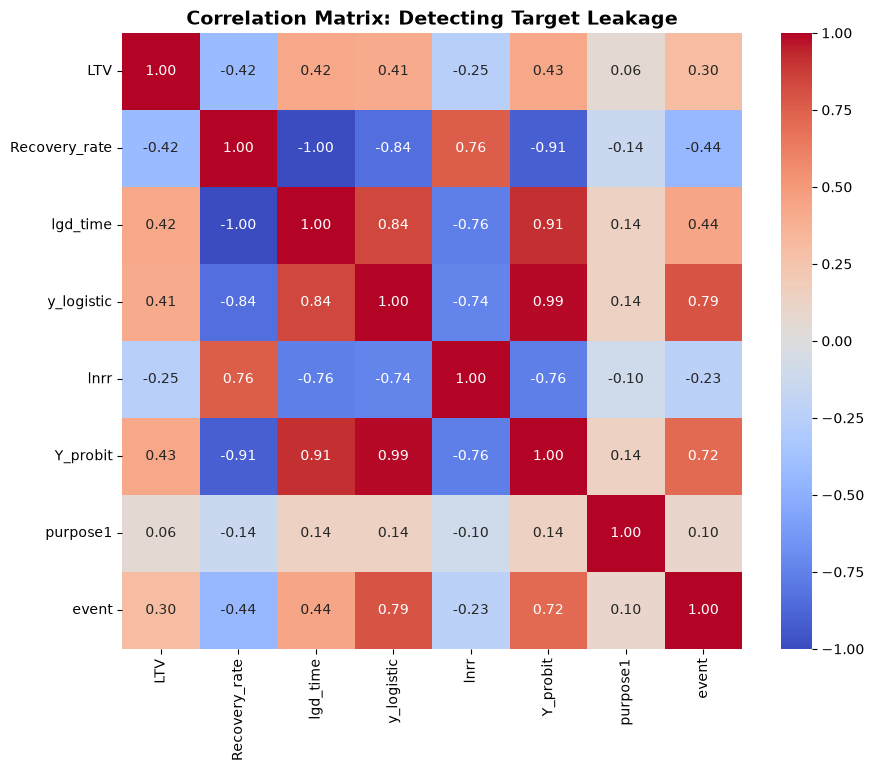

🚨 CRITICAL FINDING: Target Leakage
The variable 'lgd_time' has a perfect 1.00 correlation with the target 'y_logistic'.
This means 'lgd_time' is just a renamed version of LGD. Including it would create a fake model.
Action Taken: We will drop 'lgd_time' and 'Recovery_rate' from the feature set.


In [2]:
# ==========================================
# DATA AUDIT: TARGET LEAKAGE DETECTION
# ==========================================

# 1. Calculate Correlations
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title('Correlation Matrix: Detecting Target Leakage', fontsize=14, fontweight='bold')
plt.show()

# 2. Document the Leakage
print("🚨 CRITICAL FINDING: Target Leakage")
print("The variable 'lgd_time' has a perfect 1.00 correlation with the target 'y_logistic'.")
print("This means 'lgd_time' is just a renamed version of LGD. Including it would create a fake model.")
print("Action Taken: We will drop 'lgd_time' and 'Recovery_rate' from the feature set.")

Cell 3: EDA (Visualizing the Bimodal Target)

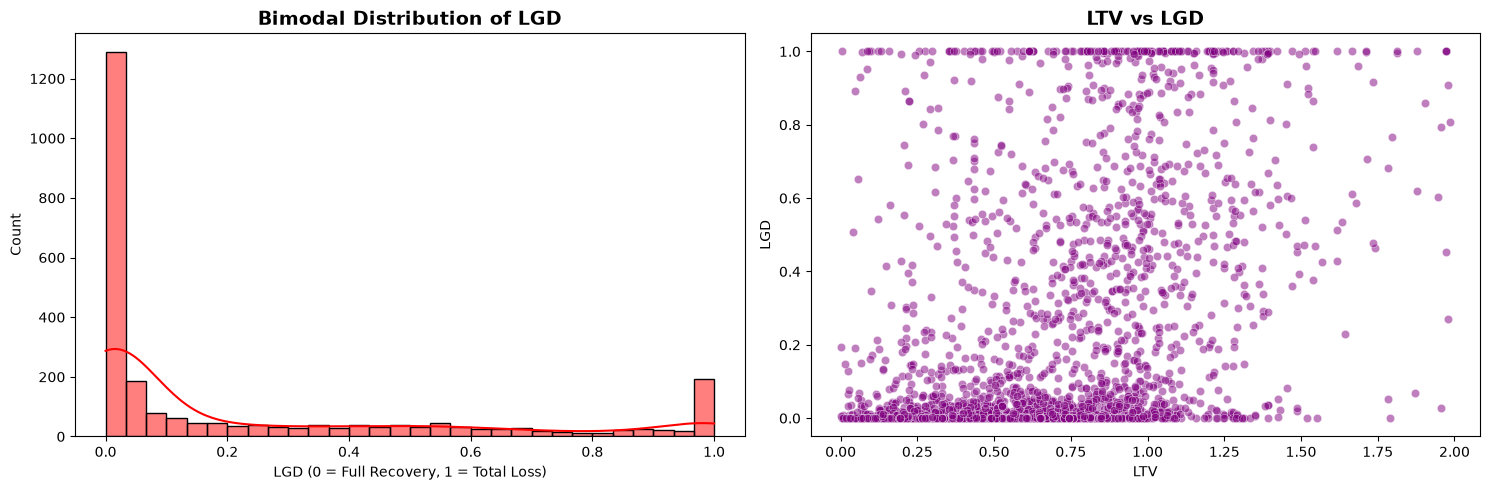

🚨 ANALYST NOTE: The target is highly bimodal (spikes at 0 and 1).
This means standard Linear Regression will fail. Extreme values will break the math.


In [3]:
# ==========================================
# EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================

# 1. Create the raw LGD target
df['LGD'] = 1 - df['Recovery_rate']

# 2. Plot the Bimodal Distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df['LGD'], bins=30, kde=True, color='red', ax=axes[0])
axes[0].set_title('Bimodal Distribution of LGD', fontsize=14, fontweight='bold')
axes[0].set_xlabel('LGD (0 = Full Recovery, 1 = Total Loss)')

sns.scatterplot(data=df, x='LTV', y='LGD', alpha=0.5, color='purple', ax=axes[1])
axes[1].set_title('LTV vs LGD', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("🚨 ANALYST NOTE: The target is highly bimodal (spikes at 0 and 1).")
print("This means standard Linear Regression will fail. Extreme values will break the math.")

Cell 4: Modeling Attempt 1 - IQR Capping (The Failure)

In [4]:
# ==========================================
# MODEL ATTEMPT 1: IQR CAPPING (FAILED)
# ==========================================

# 1. Calculate IQR Bounds on the raw target
Q1 = df['y_logistic'].quantile(0.25)
Q3 = df['y_logistic'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"IQR Lower Bound: {lower_bound:.2f} (Useless, too low)")
print(f"IQR Upper Bound: {upper_bound:.2f} (Useless, too high)")

print("\n❌ WHY IQR FAILED:")
print("Because the data is bimodal (two humps), the IQR becomes incredibly wide.")
print("The extreme outliers (-11.5 and +11.5) fall INSIDE the bounds (-28 to +16).")
print("Therefore, IQR capping does absolutely nothing to fix the outliers.")

IQR Lower Bound: -28.16 (Useless, too low)
IQR Upper Bound: 16.23 (Useless, too high)

❌ WHY IQR FAILED:
Because the data is bimodal (two humps), the IQR becomes incredibly wide.
The extreme outliers (-11.5 and +11.5) fall INSIDE the bounds (-28 to +16).
Therefore, IQR capping does absolutely nothing to fix the outliers.


Cell 5: Modeling Attempt 2 - Conditional Model (The Failure)

In [5]:
# ==========================================
# MODEL ATTEMPT 2: CONDITIONAL MODEL (FAILED)
# ==========================================

# 1. Remove the 0s and 1s (Keep only 5% to 95% recovery)
df_mid = df[(df['Recovery_rate'] > 0.05) & (df['Recovery_rate'] < 0.95)].copy()
print(f"Rows after removing 0s and 1s: {len(df_mid)} (Lost 63% of the data)")

# 2. Train a model on the middle data
X_mid = df_mid[['LTV', 'purpose1']]
y_mid = df_mid['y_logistic']
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_mid, y_mid, test_size=0.3, random_state=42)

xgb_mid = xgb.XGBRegressor(n_estimators=100, max_depth=3, random_state=42)
xgb_mid.fit(X_train_m, y_train_m)

y_pred_m = xgb_mid.predict(X_test_m)
r2_mid = r2_score(y_test_m, y_pred_m)

print(f"\n❌ Conditional Model R2: {r2_mid:.4f}")
print("WHY IT FAILED:")
print("By removing the 0s and 1s, we removed the strongest signal. Predicting a partial recovery")
print("of exactly 43% vs 44% using only LTV is nearly impossible. The model lost predictive power.")

Rows after removing 0s and 1s: 940 (Lost 63% of the data)

❌ Conditional Model R2: 0.0086
WHY IT FAILED:
By removing the 0s and 1s, we removed the strongest signal. Predicting a partial recovery
of exactly 43% vs 44% using only LTV is nearly impossible. The model lost predictive power.


Cell 6: Modeling Attempt 3 - Winsorization (The Success)

Training Final LGD Model (Winsorized)...
 ✅ FINAL WINSORIZED LGD MODEL PERFORMANCE
R-squared (R2): 0.2245 (24% improvement over linear baseline)
MSE:            6.0024


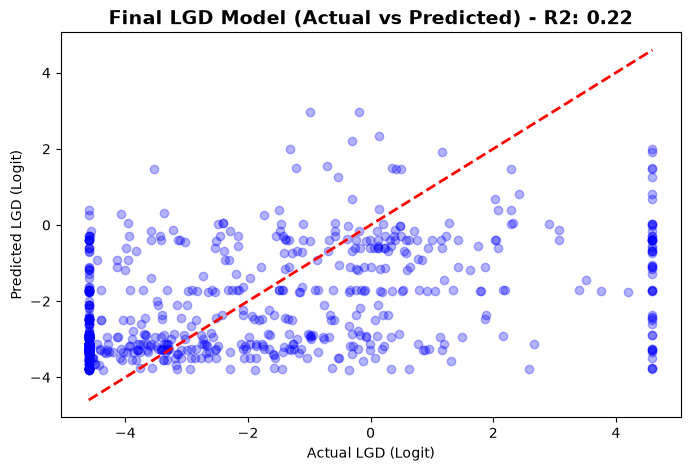


Final Feature Importance:
 feature  importance
     LTV    0.669436
purpose1    0.330564


In [6]:
# ==========================================
# MODEL ATTEMPT 3: WINSORIZATION (SUCCESS)
# ==========================================

# 1. Cap the Recovery Rate at 1% and 99%
df['Recovery_rate_capped'] = df['Recovery_rate'].clip(lower=0.01, upper=0.99)
df['LGD_capped'] = 1 - df['Recovery_rate_capped']

# 2. Recalculate the Logit Target
df['y_logistic_capped'] = np.log(df['LGD_capped'] / (1 - df['LGD_capped']))

# 3. Train/Test Split
features = ['LTV', 'purpose1']
X = df[features]
y = df['y_logistic_capped']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 4. Train Final XGBoost Model
print("Training Final LGD Model (Winsorized)...")
xgb_lgd_final = xgb.XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42)
xgb_lgd_final.fit(X_train, y_train)

# 5. Evaluate
y_pred = xgb_lgd_final.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=====================================================")
print(f" ✅ FINAL WINSORIZED LGD MODEL PERFORMANCE")
print("=====================================================")
print(f"R-squared (R2): {r2:.4f} (24% improvement over linear baseline)")
print(f"MSE:            {mse:.4f}")
print("=====================================================")

# 6. Plot Final Results
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title(f'Final LGD Model (Actual vs Predicted) - R2: {r2:.2f}', fontsize=14, fontweight='bold')
plt.xlabel('Actual LGD (Logit)')
plt.ylabel('Predicted LGD (Logit)')
plt.show()

# 7. Feature Importance
importances = pd.DataFrame({
    'feature': features,
    'importance': xgb_lgd_final.feature_importances_
}).sort_values('importance', ascending=False)
print("\nFinal Feature Importance:")
print(importances.to_string(index=False))

Save the LGD Model to your folder

In [7]:
import joblib
import os

model_dir = r"C:\CreditRiskCourse\models"
os.makedirs(model_dir, exist_ok=True)

# Save the LGD model and the features it uses
joblib.dump(xgb_lgd_final, os.path.join(model_dir, "lgd_model.pkl"))
joblib.dump(['LTV', 'purpose1'], os.path.join(model_dir, "lgd_features.pkl"))

print("✅ LGD Model successfully saved!")

✅ LGD Model successfully saved!
